We can adapt equation 3. Note that we are assuming the same lattice constant in both directions, and that $t_\pm = t'(1\pm \delta)$

Also, the convention being used here is that spin up is $s=0$ and spin down is $s=1$ such that $(-1)^s$ varies appropriately.

In [ ]:
import numpy as np


def H_s(k, a1, a2, s, t, a, tminus, tplus, U, dm):
    """
    Diagonal block from HFA Hamiltonian in Eq. 3.

    Args:
        k (2x1 vector): momentum vector
        a1 (2x1 vector): first lattice vector
        a2 (2x1 vector): second lattice vector
        s (int): spin of this block
        t (float): nn hopping integral
        a (float): lattice constant
        tminus (float): hopping integral in the a1 direction
        tplus (float): hopping integral in the a2 direction
        U (float): on-site Hubbard interaction
        dm (float): altermagnetic order parameter

    Returns: 
        2x2 numpy array: diagonal block of the Hamiltonian for spin s
    """
    hAAs = -2 * tminus * np.cos(np.dot(k, a1)) - 2 * tplus * np.cos(np.dot(k, a2)) - (-1)**s * U * dm
    hBBs = -2 * tplus * np.cos(np.dot(k, a1)) - 2 * tminus * np.cos(np.dot(k, a2)) + (-1)**s * U * dm
    hABs = -2 * t * (np.cos(k[0] * a) + np.cos(k[1] * a))
    hBAs = np.conjugate(hABs) # complex conj. but it's real so it'll just output the same thing

    return np.array([[hAAs, hABs], [hBAs, hBBs]])

# def fermi_dist(epsilon, mu, beta):
#     """
#     Fermi-Dirac distribution, returns average number at state with epsilon, with chemical potential mu

#     ARgs:
#         epsilon (float): energy of state
#         mu (float): chemical potential of state
#         beta (float): k_B * T

#     Returns:
#        float: average number at state
#     """
#     return 1 / (np.exp(beta * (epsilon - mu)) + 1)

def diagonalize_H(k_list, N, a1, a2, t, a, tminus, tplus, U, dm_in):
    """
    In the same order as the k_list momenta, we diagonalize each H(k) and store the energies and eigenfunctions.
    Faster than diagonalizing in all of the self-consistency equations and lets us calculate the Fermi energy easier too.

    Quadruples the k_list grid as we have four eigenvalues per momentum

    NOTE: swapping the component order of the down eigenvectors makes it possible to do equation S3 without tracking which is which.
    The issue with this is obviously the eigenvectors are not actually eigenvectors.

    Args:
        k_list (2xN list of float): grid of momenta
        N: number of sites
        a1 (2x1 vector): first lattice vector
        a2 (2x1 vector): second lattice vector
        s_list (int list): spins of each block
        t (float): nn hopping integral
        a (float): lattice constant
        tminus (float): hopping integral in the a1 direction
        tplus (float): hopping integral in the a2 direction
        U (float): on-site Hubbard interaction
        dm_in (float): input altermagnetic order parameter
        mu (float): chemical potential

    Returns:
        list of floats: sorted list of eigenvalues (energies) for each k (same order as k_list, ordered as up, down with 2 eigenvalues per k)
        list of 2x2 numpy arrays: sorted list of eigenvectors (sorted by energy) for each k (ordered as up, down with 2 eigenvectors per k)
        2x(4N) list of float: grid of sorted momenta according to energies
    """
    energies = []
    eigenvectors = []
    new_k_list = []

    for k in k_list:
        H_up = H_s(k, a1, a2, 0, t, a, tminus, tplus, U, dm_in)
        epsilons, psis = np.linalg.eigh(H_up)
        energies.extend(epsilons)
        eigenvectors.extend(psis.T)
        new_k_list.extend([k, k])  # Add the same k twice for the two eigenvalues


        H_down = H_s(k, a1, a2, 1, t, a, tminus, tplus, U, dm_in)
        epsilons, psis = np.linalg.eigh(H_down)
        energies.extend(epsilons)
        eigenvectors.extend(psis.T)
        new_k_list.extend([k, k])  # Add the same k twice for the two eigenvalues

    sorted_indices = np.argsort(energies)
    sorted_energies = [energies[i] for i in sorted_indices]
    sorted_eigenvectors = [eigenvectors[i] for i in sorted_indices]
    sorted_k_list = [new_k_list[i] for i in sorted_indices]

    return sorted_energies, sorted_eigenvectors, sorted_k_list

def fermi_dist(epsilon, mu):
    """
    Fermi-Dirac distribution, returns average number at state with epsilon, with chemical potential mu
    Seeing as we're doing a low temperature calculation, we may as well just use the Heaviside function

    ARgs:
        epsilon (float): energy of state
        mu (float): chemical potential of state
        beta (float): k_B * T

    Returns:
       float: average number at state
    """
    return 1.0 if epsilon < mu else 0.0

def fermi_energy(sorted_energies, n, N):
    """
    Using n = (# of eigenvalues < E_F) / N, we can get a Fermi energy from the sorted energies

    Args:
        sorted_energies (list of floats): 
        n (float): electron density
        N (int): number of sites/number of unique momenta (note that we have 4 energies per momentum)
    
    Returns:
        float: Fermi energy
    """

    num_energies = int(np.floor(n * 2 * N))
    if num_energies < (4 * N - 1):
        print(sorted_energies[num_energies], sorted_energies[num_energies + 1])
        return (sorted_energies[num_energies] + sorted_energies[num_energies + 1]) / 2
    return sorted_energies[-1]

    

def t_plusminus(tp, delta):
    """
    Calculate tplus and tminus based on tp and delta

    Args:
        tp (float): hopping integral
        delta (float): parameter for hopping

    Returns:
        tuple: (tplus, tminus)
    """
    tplus = tp * (1 + delta)
    tminus = tp * (1 - delta)
    return tplus, tminus


## Self-consistency equations

Equations (S2) and (S3)

In [ ]:
def self_consistency_dm(sorted_energies, sorted_eigenvectors, N, mu):
    """
    Using equation (S2), we go through every element in the k_list to get the altermagnetic order parameter dm

    Args:
        k_list (2xN list of float): grid of momenta
        N: number of sites
        a1 (2x1 vector): first lattice vector
        a2 (2x1 vector): second lattice vector
        s_list (int list): spins of each block
        t (float): nn hopping integral
        a (float): lattice constant
        tminus (float): hopping integral in the a1 direction
        tplus (float): hopping integral in the a2 direction
        U (float): on-site Hubbard interaction
        dm_in (float): input altermagnetic order parameter
        mu (float): chemical potential

    Returns:
        float: output altermagnetic order parameter dm
    """

    dm_out = 0
    for epsilon, psi in zip(sorted_energies, sorted_eigenvectors):
        dm_out += (np.abs(psi[0]) ** 2 - np.abs(psi[1]) ** 2) * fermi_dist(epsilon, mu) # each term in sum (upper left block)           
    
    return dm_out / (4 * N)

def self_consistency_mu(sorted_energies, N, mu):
    """
    Using equation (S3), we go through every element in the k_list to get the average number of electrons n

    Args:
        sorted_energies (list of floats): sorted list of eigenvalues (energies) for each k (same order as k_list, ordered as up, down with 2 eigenvalues per k)
        N (int): number of sites
        mu (float): chemical potential

    Returns:
        float: average number of electrons n
    """

    n = 0
    
    for energy in sorted_energies:
        n += fermi_dist(energy, mu) # each term in sum (lower right block)        
        
    return n / (2 * N)

# Parameters

In [158]:
a = 1
k = np.array([1, 1])
a1 = np.array([a, a])
a2 = np.array([a, -a])
tp = 0.3
t = 1.0
delta = 0.9
tplus, tminus = t_plusminus(tp, delta)
U = 3.5
dm_in = 0.1
N_x = 20
N_y = 20 # not strictly in x and y directions apart from in the unit square...
N=N_x*N_y
n = 1.0
mu = 0.0

The unit cell has lattice vectors $a_1 = (a, a), a_2 = (a, -a)$, so we get RLVs:

$$
a_1 \cdot b_1 = 2\pi \\
a_2 \cdot b_1 = 0
$$

and

$$
a_1 \cdot b_2 = 0 \\
a_2 \cdot b_2 = 2\pi
$$

which is fulfilled by 

$$
b_1 = \left( \frac \pi a,\frac  \pi a\right)
$$

$$
b_2 = \left(\frac \pi a, -\frac \pi a\right)
$$

To construct our meshgrid in reciprocal space, we need to fill the diamond between $(\pi/a, \pi/a), (\pi/a, -\pi/a), (-\pi/a, \pi/a), (-\pi/a, -\pi/a)$. The easiest way to do that is to construct a unit square, then map each unit square into the RLV basis (each unit square value becomes a component in the RLV basis) and finally scale it by $\pi/a$.

We also don't want to include the edges twice so we can take $N_x+1$ or $N_y+1$ points and ignore the last one for each axis.

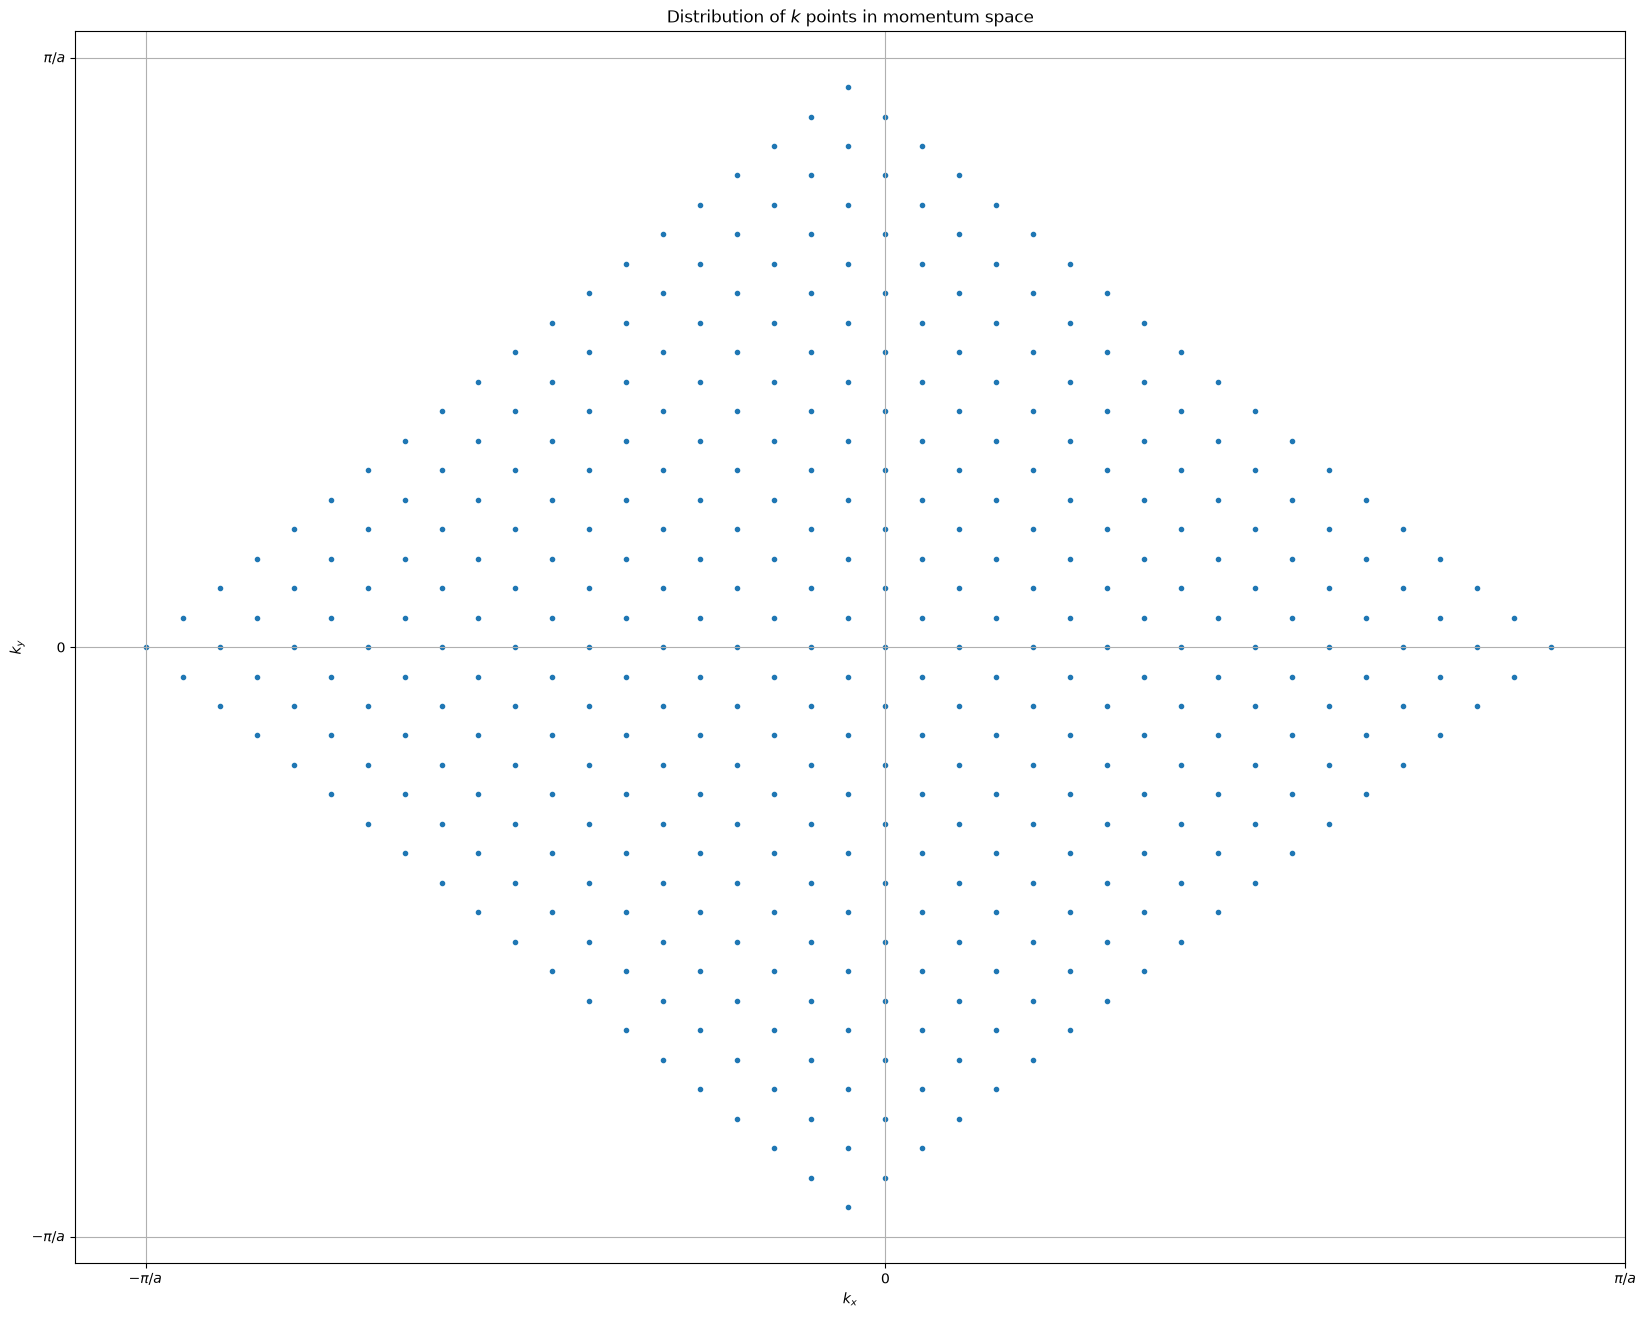

In [159]:
import matplotlib.pyplot as plt
# construct a unit square
unit_x, unit_y = np.meshgrid(np.linspace(-1/2, 1/2, N_x+1)[:-1], np.linspace(-1/2, 1/2, N_y+1)[:-1]) # we do NOT want to repeat the endpoints

k_list_x = np.pi / a * (unit_x + unit_y)
k_list_y = np.pi / a * (unit_x - unit_y)

fig = plt.figure(figsize=(20,16))
ticks = [-np.pi / a, 0, np.pi / a]
labels = [r'$-\pi/a$', '0', r'$\pi/a$']
plt.scatter(k_list_x, k_list_y, marker=".")
plt.title(r"Distribution of $k$ points in momentum space")
plt.grid(True)
plt.xticks(ticks, labels)
plt.yticks(ticks, labels)
plt.xlabel(r"$k_x$")
plt.ylabel(r"$k_y$")
plt.show()


In [160]:
# N_x = 200
# N_y = 200 # not strictly in x and y directions apart from in the unit square...
# # construct a unit square
# unit_x, unit_y = np.meshgrid(np.linspace(-1/2, 1/2, N_x+1)[:-1], np.linspace(-1/2, 1/2, N_y+1)[:-1]) # we do NOT want to repeat the endpoints
# k_list_x = np.pi / a * (unit_x + unit_y)
# k_list_y = np.pi / a * (unit_x - unit_y)

# Testing

The paper uses "$t'/t=0.3$, $\delta = 0.9$, and $U/t=3.5$"

We iterate by first choosing a value for $\delta m$, then plug it into

In [161]:
k_list = list(zip(k_list_x.flatten(), k_list_y.flatten()))

# for x, y in k_list:
#     print(x, y)

H1 = H_s(k, a1, a2, 0, t, a, tminus, tplus, U, dm_in)
H2 = H_s(k, a1, a2, 1, t, a, tminus, tplus, U, dm_in)
# print(H1)
H = np.block([[H1,                  np.zeros((2,2))], 
              [np.zeros((2,2)),     H2]])
print(H)
epsilons, psis = np.linalg.eig(H)
psis_matrix = np.array(psis)
print(epsilons)
print(psis)

[[-1.46503119 -2.16120922  0.          0.        ]
 [-2.16120922  0.76440739  0.          0.        ]
 [ 0.          0.         -0.76503119 -2.16120922]
 [ 0.          0.         -2.16120922  0.06440739]]
[-2.78206526+0.j  2.08144146+0.j -2.55095212+0.j  1.85032833+0.j]
[[-0.85393251+0.j  0.52038377+0.j  0.        +0.j  0.        +0.j]
 [-0.52038377+0.j -0.85393251+0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j -0.77086118+0.j  0.63700317+0.j]
 [ 0.        +0.j  0.        +0.j -0.63700317+0.j -0.77086118+0.j]]


In [163]:
# mu_old = mu
# mu_new = mu

sorted_energies, sorted_eigenvectors, sorted_k_list = diagonalize_H(k_list, N, a1, a2, t, a, tminus, tplus, U, dm_in)

print(len(sorted_energies)/N)

mu = fermi_energy(sorted_energies, n, N)
print(mu)

self_consistency_mu(sorted_energies, N, 0.7899999999999998)

4.0
0.7899999999999998 0.7899999999999998
0.7899999999999998


1.0

# TODO: just set mu to fermi energy, we don't need this whole rigamarole with root finding :)

In [135]:
k_list_x, k_list_y = np.meshgrid(np.linspace(-np.pi/a, np.pi/a, 200), np.linspace(-np.pi/a, np.pi/a, 200))
k_list = list(zip(k_list_x.flatten(), k_list_y.flatten()))

self_consistency_dm(k_list, N, a1, a2, t, a, tminus, tplus, U, 1.0, mu)

np.float64(44.315225056117946)